In [11]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(r'C:\Users\acer\OneDrive\Desktop\Cognifyz-Internship\Dataset.csv')


print(f"Shape: {df.shape}")
df.head()

Shape: (9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


# Level 1 - Task 1: Top Cuisines

**Objective:** 
1. Determine the top 3 most common cuisines in the dataset.
2. Calculate the percentage of restaurants that serve each of the top cuisines.

In [12]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

# Load dataset
df = pd.read_csv(r'C:\Users\acer\OneDrive\Desktop\Cognifyz-Internship\Dataset.csv')

print(f"✅ Dataset loaded!")
print(f"Total Restaurants: {len(df)}")
print(f"Total Columns: {df.shape[1]}")
print(f"\nColumn Names:\n{df.columns.tolist()}")

✅ Dataset loaded!
Total Restaurants: 9551
Total Columns: 21

Column Names:
['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address', 'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Price range', 'Aggregate rating', 'Rating color', 'Rating text', 'Votes']


In [13]:
cuisines_series = df['Cuisines'].dropna().str.split(', ').explode()

print(f"Total cuisine entries: {len(cuisines_series)}")
print(f"Unique cuisines: {cuisines_series.nunique()}")
print(f"\nTop 10 cuisines (preview):")
print(cuisines_series.value_counts().head(10))

Total cuisine entries: 19710
Unique cuisines: 145

Top 10 cuisines (preview):
Cuisines
North Indian    3960
Chinese         2735
Fast Food       1986
Mughlai          995
Italian          764
Bakery           745
Continental      736
Cafe             703
Desserts         653
South Indian     636
Name: count, dtype: int64


In [14]:
# Top 3 cuisines
top_3_cuisines = cuisines_series.value_counts().head(3)

print("=" * 50)
print("🎯 TOP 3 MOST COMMON CUISINES")
print("=" * 50)
for rank, (cuisine, count) in enumerate(top_3_cuisines.items(), 1):
    print(f"{rank}. {cuisine}: {count} restaurants")

🎯 TOP 3 MOST COMMON CUISINES
1. North Indian: 3960 restaurants
2. Chinese: 2735 restaurants
3. Fast Food: 1986 restaurants


In [15]:
total_restaurants = len(df)

print("=" * 60)
print("📊 PERCENTAGE OF RESTAURANTS SERVING EACH TOP CUISINE")
print("=" * 60)
print(f"Total restaurants in dataset: {total_restaurants}\n")

for cuisine, count in top_3_cuisines.items():
    percentage = (count / total_restaurants) * 100
    print(f"{cuisine:20s} → {count:5d} restaurants → {percentage:.2f}%")

📊 PERCENTAGE OF RESTAURANTS SERVING EACH TOP CUISINE
Total restaurants in dataset: 9551

North Indian         →  3960 restaurants → 41.46%
Chinese              →  2735 restaurants → 28.64%
Fast Food            →  1986 restaurants → 20.79%


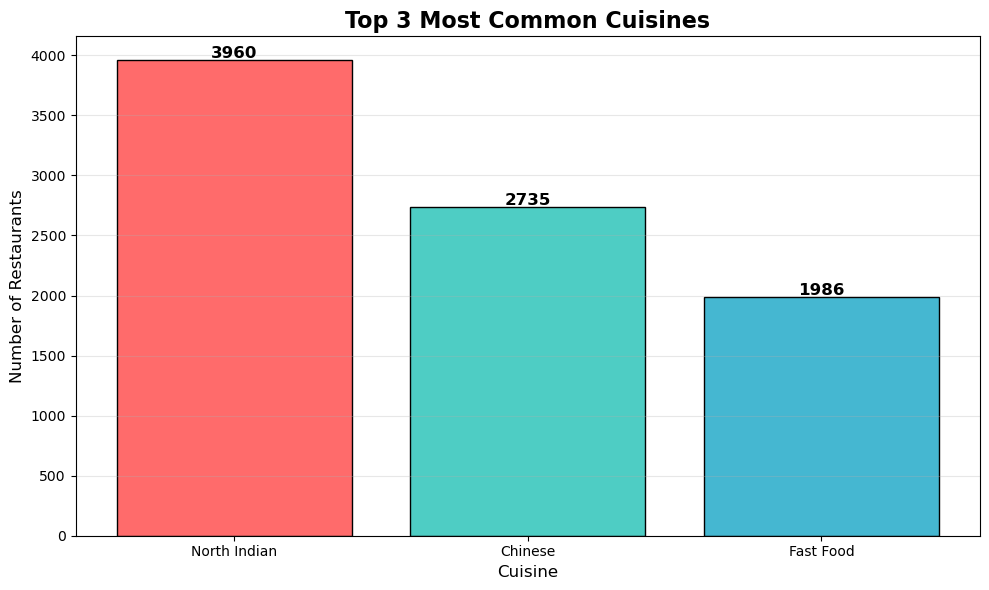

In [16]:
# Bar chart
plt.figure(figsize=(10, 6))
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']
bars = plt.bar(top_3_cuisines.index, top_3_cuisines.values, color=colors, edgecolor='black')

# Har bar ke upar count likho
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 20,
             f'{int(height)}', ha='center', fontsize=12, fontweight='bold')

plt.title('Top 3 Most Common Cuisines', fontsize=16, fontweight='bold')
plt.xlabel('Cuisine', fontsize=12)
plt.ylabel('Number of Restaurants', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

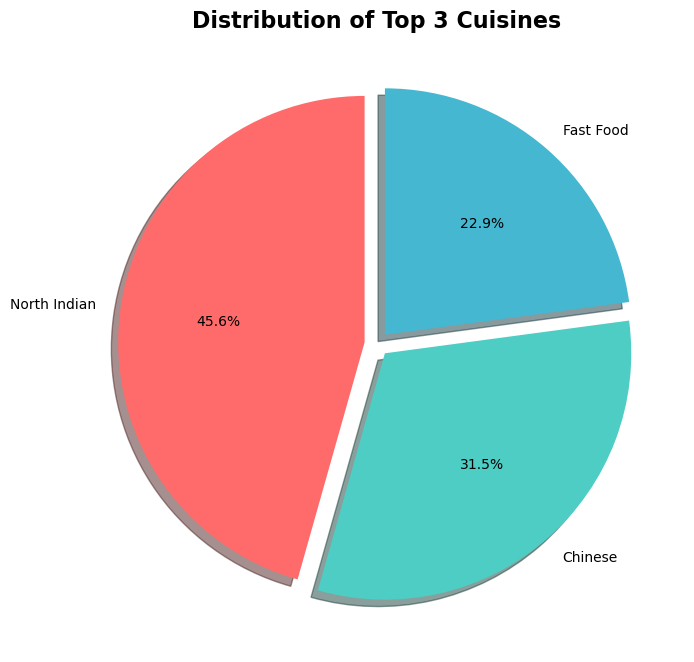

In [17]:
# Pie chart bhi bana lo
plt.figure(figsize=(8, 8))
plt.pie(top_3_cuisines.values, 
        labels=top_3_cuisines.index,
        autopct='%1.1f%%',
        colors=colors,
        startangle=90,
        explode=(0.05, 0.05, 0.05),
        shadow=True)
plt.title('Distribution of Top 3 Cuisines', fontsize=16, fontweight='bold')
plt.show()

##  Insights

- **North Indian** cuisine is the most common, served by X% of restaurants.
- **Chinese** comes second with Y%.
- **Fast Food** is third with Z%.

### Conclusion:
North Indian and Chinese cuisines dominate the restaurant market. 
These cuisines have the highest customer demand and restaurant availability.